# EMNIST: ten digit-like letter classes

Inspect the datasets exposed by `dataset_utils` for MNIST → EMNIST LoRA experiments. Both choices keep **B, G, I, L, O, Q, S, T, Y, Z**, with labels `0–9` in that order:

- `emnist`: the balanced **Letters** split, which merges uppercase and lowercase handwriting.
- `upper_emnist`: the **ByClass** split filtered to those ten uppercase class labels. Lowercase and digit classes are excluded. ByClass has unequal class counts; every selected sample is retained.

The [official EMNIST dataset](https://www.nist.gov/itl/products-and-services/emnist-dataset) provides these different splits. The selected letters share some loops and strokes with digits, but this is a visual heuristic, not a measured similarity ranking. The labels identify letters rather than digit identities.

Both loaders transpose the stored image axes to obtain upright, unmirrored `1 × 28 × 28` grayscale tensors in `[0, 1]`. On first use, torchvision downloads the official EMNIST archive into `paths.dataset_dir`; subsequent runs reuse it. Run the cells from the repository root or `notebooks` using the project's Python environment.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch
from torchvision.datasets import EMNIST
from IPython.display import Markdown, display

repo_root = Path.cwd().resolve()
if not (repo_root / "pyproject.toml").exists():
    repo_root = repo_root.parent
if not (repo_root / "pyproject.toml").exists():
    raise FileNotFoundError("Run this notebook from the repository root or notebooks directory.")
sys.path.insert(0, str(repo_root / "src"))

from domain_knowledge_analysis import utils
from domain_knowledge_analysis.utils.dataset_utils import (
    EMNIST_LETTERS,
    create_train_validation_datasets,
)

## Settings and dataset loading

Set `DATASET` to **`"upper_emnist"`** for uppercase letters or **`"emnist"`** for the original mixed-case subset, then run all cells. `USE_TEST_SPLIT` chooses the pool for the galleries; the count plot always shows the actual training, validation, and official test splits.

With the default `train_split=0.8`:

| Dataset | Full training pool | Training | Validation | Official test |
| --- | ---: | ---: | ---: | ---: |
| `emnist` | 48,000 | 38,400 | 9,600 | 8,000 |
| `upper_emnist` | 89,033 | 71,226 | 17,807 | 14,868 |

Uppercase-only has more samples because it uses the larger ByClass split rather than the balanced Letters split. Validation uses the existing seeded random split, so it does not enforce equal class counts.

In [2]:
DATASET = "upper_emnist"  # "upper_emnist" or "emnist"
USE_TEST_SPLIT = False
EXAMPLES_PER_CLASS = 6
SAMPLE_SEED = 123

if DATASET not in {"emnist", "upper_emnist"}:
    raise ValueError("Select 'emnist' or 'upper_emnist'.")
uppercase_only = DATASET == "upper_emnist"
case_description = "uppercase only (ByClass)" if uppercase_only else "mixed case (Letters)"

config = utils.load_config(repo_root / "config" / "vae_mnist.yaml")
config["dataset"]["name"] = DATASET
train_dataset, validation_dataset = create_train_validation_datasets(config, DATASET)
training_pool = train_dataset.dataset
test_dataset = utils.create_dataset(config, DATASET, train=False)
dataset = test_dataset if USE_TEST_SPLIT else training_pool
split_name = "test" if USE_TEST_SPLIT else "training pool"
classes = list(EMNIST_LETTERS)
class_names = {letter: letter if uppercase_only else f"{letter}/{letter.lower()}" for letter in classes}
source_classes = EMNIST.classes_split_dict[training_pool.split]

assert training_pool.classes == test_dataset.classes == classes
expected_pool, expected_test = {"emnist": (48_000, 8_000), "upper_emnist": (89_033, 14_868)}[DATASET]
assert len(training_pool) == expected_pool and len(test_dataset) == expected_test
assert set(training_pool.targets.tolist()) == set(test_dataset.targets.tolist()) == set(range(10))
assert set(train_dataset.indices).isdisjoint(validation_dataset.indices)
if not uppercase_only:
    assert torch.equal(torch.bincount(training_pool.targets), torch.full((10,), 4_800))
    assert torch.equal(torch.bincount(test_dataset.targets), torch.full((10,), 800))

image, label = dataset[0]
assert tuple(image.shape) == tuple(config["dataset"]["shape"]) == (1, 28, 28)
assert image.dtype == torch.float32 and 0 <= image.min() <= image.max() <= 1
print(f"Dataset: {DATASET} — {case_description}")
print(f"Training pool: {len(training_pool):,}; training: {len(train_dataset):,}; "
      f"validation: {len(validation_dataset):,}; test: {len(test_dataset):,}")
print(f"Gallery split: {split_name}; tensor: {tuple(image.shape)}; dtype: {image.dtype}")
print(f"Label mapping: {dict(enumerate(classes))}")

Dataset: upper_emnist — uppercase only (ByClass)
Training pool: 89,033; training: 71,226; validation: 17,807; test: 14,868
Gallery split: training pool; tensor: (1, 28, 28); dtype: torch.float32
Label mapping: {0: 'B', 1: 'G', 2: 'I', 3: 'L', 4: 'O', 5: 'Q', 6: 'S', 7: 'T', 8: 'Y', 9: 'Z'}


## Why these letters?

The digit column gives an illustrative analogy, not a training label or a claim that every sample has that shape. There is no requirement to cover every MNIST digit once: I and L both offer simple strokes resembling 1. For `emnist`, lowercase b can resemble 6 while capital B resembles 8. `upper_emnist` retains only the uppercase class labels, so its gallery has no lowercase classes. The table reports the original class ID for the chosen EMNIST split.

In [3]:
# Illustrative analogies used only for display; labels remain alphabetical.
comparison_digits = {"B": 8, "G": 6, "I": 1, "L": 1, "O": 0,
                     "Q": 9, "S": 5, "T": 7, "Y": 4, "Z": 2}
rows = ["| Class label | Letter | Original EMNIST label | Digit analogy |",
        "| --- | --- | --- | --- |"]
for label, letter in enumerate(classes):
    source_letter = letter if uppercase_only else letter.lower()
    original_label = source_classes.index(source_letter)
    rows.append(f"| {label} | {class_names[letter]} | {original_label} | {comparison_digits[letter]} |")
display(Markdown("\n".join(rows)))

| Class label | Letter | Original EMNIST label | Digit analogy |
| --- | --- | --- | --- |
| 0 | B | 11 | 8 |
| 1 | G | 16 | 6 |
| 2 | I | 18 | 1 |
| 3 | L | 21 | 1 |
| 4 | O | 24 | 0 |
| 5 | Q | 26 | 9 |
| 6 | S | 28 | 5 |
| 7 | T | 29 | 7 |
| 8 | Y | 34 | 4 |
| 9 | Z | 35 | 2 |

## Class counts in the actual splits

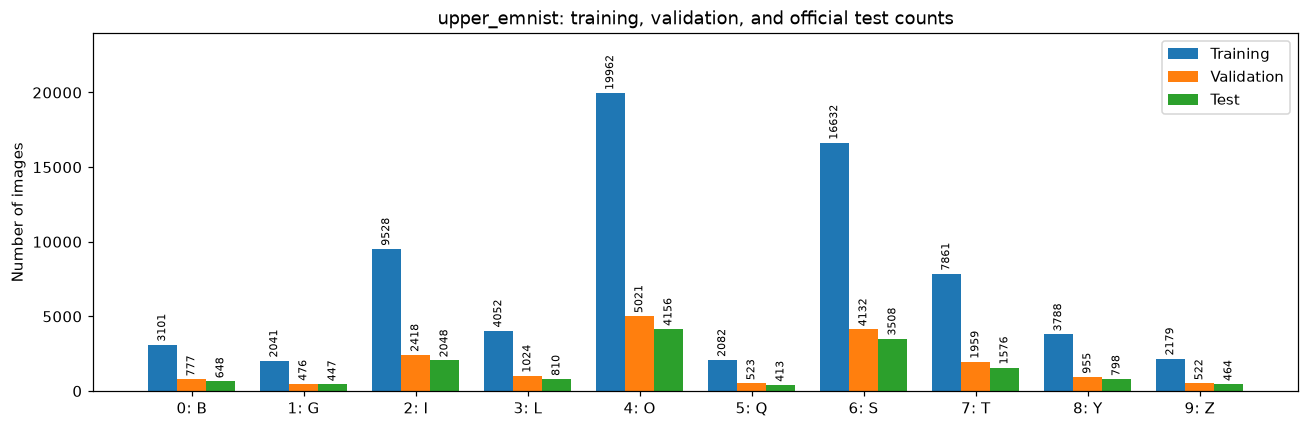

In [4]:
counts = {
    "Training": torch.bincount(training_pool.targets[train_dataset.indices], minlength=10),
    "Validation": torch.bincount(training_pool.targets[validation_dataset.indices], minlength=10),
    "Test": torch.bincount(test_dataset.targets, minlength=10),
}
positions = torch.arange(len(classes))
fig, ax = plt.subplots(figsize=(12, 4))
for offset, (name, values) in enumerate(counts.items()):
    bars = ax.bar(positions + (offset - 1) * 0.26, values, width=0.26, label=name)
    ax.bar_label(bars, fontsize=7, padding=2, rotation=90)
ax.set_xticks(positions, [f"{label}: {class_names[letter]}" for label, letter in enumerate(classes)])
ax.set_ylabel("Number of images")
ax.set_ylim(0, max(counts["Training"]).item() * 1.2)
ax.set_title(f"{DATASET}: training, validation, and official test counts")
ax.legend()
fig.tight_layout()
plt.show()

## Multiple handwriting samples per letter

The samples are reproducible from `SAMPLE_SEED`. These tensors come directly from `utils.create_dataset`; plotting applies no extra rotation, reflection, scaling, or thresholding. Change the seed to inspect more handwriting styles. Row labels show lowercase variants only when `DATASET = "emnist"`.

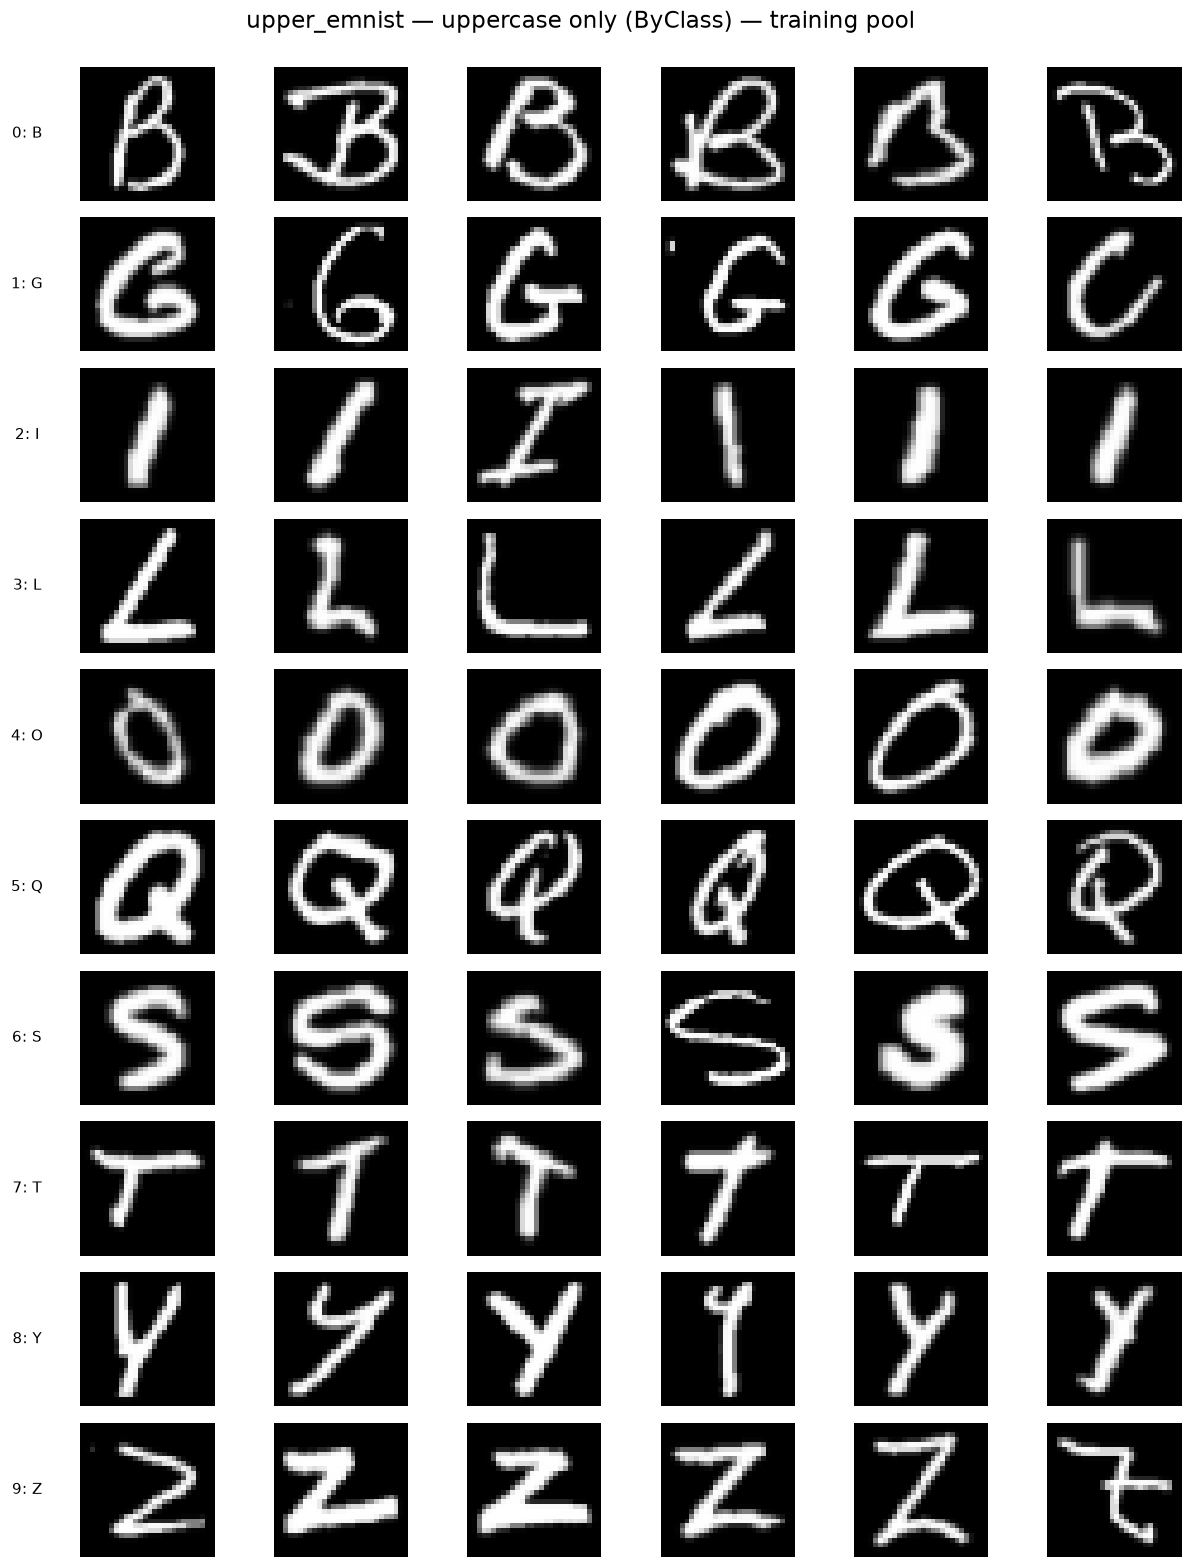

In [5]:
def select_class_samples(targets, class_label, count, generator):
    candidates = torch.where(targets == class_label)[0]
    if count < 1 or count > len(candidates):
        raise ValueError(f"Request between 1 and {len(candidates)} samples for class {class_label}.")
    return candidates[torch.randperm(len(candidates), generator=generator)[:count]].tolist()


def show_image(axis, image):
    axis.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axis.set_xticks([])
    axis.set_yticks([])
    for spine in axis.spines.values():
        spine.set_visible(False)


generator = torch.Generator().manual_seed(SAMPLE_SEED)
fig, axes = plt.subplots(len(classes), EXAMPLES_PER_CLASS,
                         figsize=(2 * EXAMPLES_PER_CLASS, 1.45 * len(classes)), squeeze=False)
for class_label, letter in enumerate(classes):
    indices = select_class_samples(dataset.targets, class_label, EXAMPLES_PER_CLASS, generator)
    for column, index in enumerate(indices):
        image, observed_label = dataset[index]
        assert observed_label == class_label
        show_image(axes[class_label, column], image)
    axes[class_label, 0].set_ylabel(f"{class_label}: {class_names[letter]}",
                                  rotation=0, labelpad=35, va="center")
fig.suptitle(f"{DATASET} — {case_description} — {split_name}", fontsize=15)
fig.tight_layout(rect=(0.04, 0, 1, 0.98))
plt.show()

## MNIST and EMNIST side by side

Each row compares two MNIST digit examples with two examples of the analogous letter class. Both datasets use the same grayscale scale and preprocessing. The digit analogies help assess the domain shift; they do not change either dataset's labels or filter individual handwriting samples.

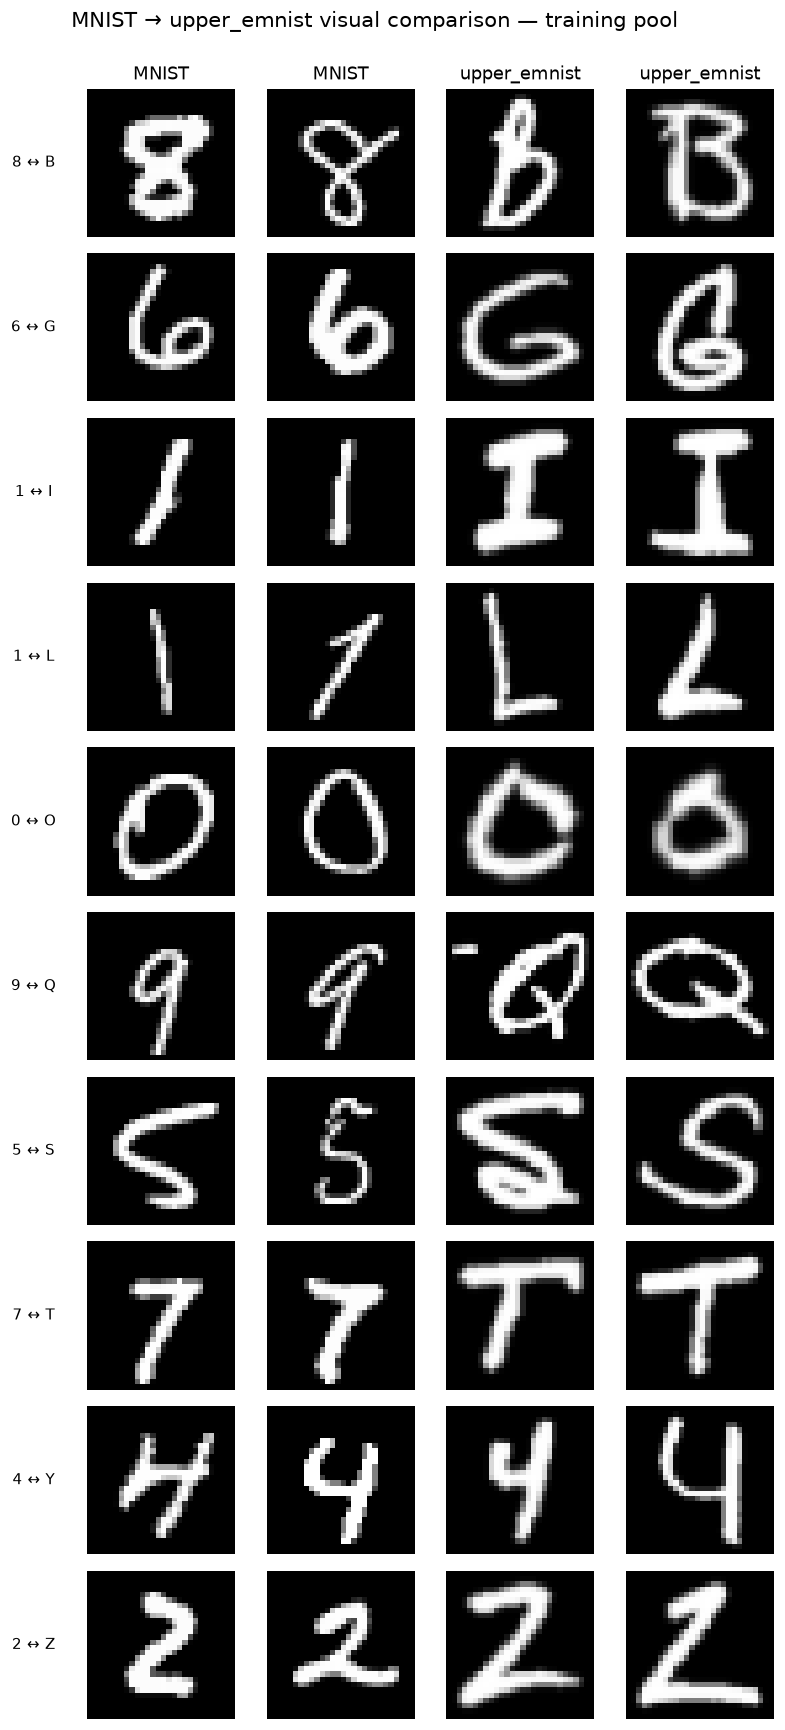

In [6]:
mnist = utils.create_dataset(config, "mnist", train=not USE_TEST_SPLIT)
generator = torch.Generator().manual_seed(SAMPLE_SEED)
fig, axes = plt.subplots(len(classes), 4, figsize=(8, 1.6 * len(classes)), squeeze=False)
for class_label, letter in enumerate(classes):
    digit = comparison_digits[letter]
    digit_indices = select_class_samples(mnist.targets, digit, 2, generator)
    letter_indices = select_class_samples(dataset.targets, class_label, 2, generator)
    for column, index in enumerate(digit_indices):
        show_image(axes[class_label, column], mnist[index][0])
    for column, index in enumerate(letter_indices, start=2):
        show_image(axes[class_label, column], dataset[index][0])
    axes[class_label, 0].set_ylabel(f"{digit} ↔ {class_names[letter]}", rotation=0, labelpad=35, va="center")
for axis, title in zip(axes[0], ["MNIST", "MNIST", DATASET, DATASET]):
    axis.set_title(title)
fig.suptitle(f"MNIST → {DATASET} visual comparison — {split_name}", fontsize=14)
fig.tight_layout(rect=(0.06, 0, 1, 0.98))
plt.show()

## Using the selected subset

```python
training_pool = utils.create_dataset(config, DATASET, train=True)
held_out_test = utils.create_dataset(config, DATASET, train=False)
# config["dataset"]["name"] is already DATASET in this notebook.
train_loader, validation_loader = utils.create_training_dataloaders(config)
test_loader = utils.create_testing_dataloaders(config)
```

Both names work with the scoring and calibration loaders. The configuration controls the seed, training fraction, batch size, and likelihood preprocessing. This notebook uses Bernoulli preprocessing from `vae_mnist.yaml`. Continuous Bernoulli also applies the repository's usual deterministic uniform dequantization.

For MNIST → uppercase EMNIST LoRA, keep top-level `dataset.name: mnist` as the source and select this target:

```yaml
lora:
  transformed_dataset:
    name: upper_emnist
    train_split: 0.8
    shape: [1, 28, 28]
```

The complete configuration is `config/lora_vae_mnist_upper_emnist.yaml`; it inherits the current EMNIST LoRA training and regularizer settings. For mixed case, use `name: emnist` and `config/lora_vae_mnist_emnist.yaml`. A registered dataset name loads that target directly, including its official test set; leftover `type` and `intensity` fields are ignored. Source evaluation continues to use MNIST. Rotated MNIST remains available with `name: rotated_mnist`, `type: rotation`, and the desired `intensity`. This notebook does not launch training.